In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from scipy import stats
import os

In [2]:
experiment = 'full_pipeline'
file = f'../experiments/{experiment}/final_data.csv'
df = pd.read_csv(file)
df = df[~df['fish'].str.contains('fishctrl|fishwater', case=False, regex=True, na=False)]

sample_map_int = {1:5, 2:6, 3:7, 4:8, 5:9, 6:10, 7:11, 8:12, 9:13, 10:14,
                  11:16, 12:17, 13:18, 14: 20, 15: 22, 16: 24, 17: 25, 18:26}

# Convert sample number to time.
df['time'] = df['sample'].map(sample_map_int)

In [3]:
# 2. Keep only sample 1
df_sample1 = df[df['sample'] == 1].copy()
print(f"\nNumber of fish with none_barcode data: {len(df_sample1)}")


Number of fish with none_barcode data: 365


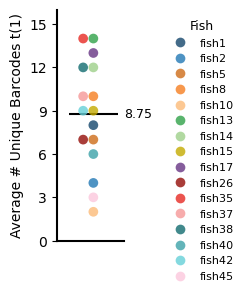

In [4]:
# ============================================
# PLOT 1: Number of Unique Barcodes per Fish
# ============================================
# Count unique barcodes per fish across all replicates
barcode_counts = (
    df_sample1.groupby('fish')['barcode']
    .nunique()
    .reset_index(name='unique_barcode_count')
)
# Build color dictionary from your provided palette
unique_fish = sorted(df['fish'].unique())
master_fish_order = [
    "fish1", "fish2", "fish4", "fish5", "fish8",
    "fish10", "fish12", "fish13", "fish14", "fish15",
    "fish16", "fish17", "fish18", "fish22", "fish26",
    "fish35", "fish37", "fish38", "fish40", 
    "fish42", "fish43", "fish44", "fish45", "fish50", "fish51" 
]
master_colors = [
    "#14466C", "#2278B5", "#AEC7E8", #blues
    "#CD6C18", "#F57F20", "#FCBB78", #oranges
    "#1A702E", "#2FA148", "#9ED08A", #greens
    "#C4AA00", "#FFE116", #yellows
    "#673484", "#9268AD", "#C5B1D6", #purples
    "#940C07","#E62923", "#F69797", #reds
    "#116C70", "#3CA1A8", "#65D0D8", #teals
    "#CD2A91", "#E580BD", "#FCC7DC", #pinks
    "#282B3D", "#7C83BC" #periwinkles
]
color_map = dict(zip(master_fish_order, master_colors))

# ============================================
# Order fish numerically for legend
# ============================================
# Extract numeric part and sort (using raw string to avoid warning)
barcode_counts['fish_num'] = barcode_counts['fish'].str.extract(r'(\d+)').astype(int)
barcode_counts = barcode_counts.sort_values('fish_num')
# Create ordered categorical for proper legend ordering
fish_order = barcode_counts.sort_values('fish_num')['fish'].tolist()
barcode_counts['fish'] = pd.Categorical(barcode_counts['fish'], categories=fish_order, ordered=True)

mean_value = barcode_counts['unique_barcode_count'].mean()
fig, ax = plt.subplots(figsize=(1.25, 3))
sns.swarmplot(
    data=barcode_counts,
    x=[0] * len(barcode_counts),
    y='unique_barcode_count',
    hue='fish',
    palette=color_map,
    size=7,
    alpha=0.8,
    ax=ax,
    dodge=False,
    hue_order=fish_order  # Apply the numerical order to the plot
)
# Add legend with proper ordering
ax.legend(
    title='Fish',
    bbox_to_anchor=(1.05, 1),
    loc='upper left',
    frameon=False,
    fontsize=8,
    title_fontsize=9
)
ax.hlines(y=mean_value, xmin=-0.2, xmax=0.2, color='black', linewidth=1.5)
ax.text(0.25, mean_value, f"{mean_value:.2f}",
        va='center', ha='left', fontsize=9, color='black')
ax.set_xlim(-0.3, 0.5)
ax.set_ylim(0, 16)

# For ALL TIME: Set y-axis ticks from 0 to 20, every 4, integers only
ax.set_yticks([0, 3, 6, 9, 12, 15])
ax.set_yticklabels([0, 3, 6, 9, 12, 15])

ax.set_ylabel("Average # Unique Barcodes t(1)", fontsize=10)
ax.set_xticks([])
ax.set_xlabel('')
for s in ['top', 'right', 'bottom']:
    ax.spines[s].set_visible(False)
ax.spines['left'].set_linewidth(1.5)
ax.plot([-0.3, 0.25], [0, 0], color='black', linewidth=1.5, clip_on=False)

#plt.savefig("ColoredViolin_t1_v4.svg", bbox_inches='tight', transparent=True)
#plt.savefig("ColoredViolin_t1_v4.png", dpi=600, bbox_inches='tight', transparent=True)
plt.show()

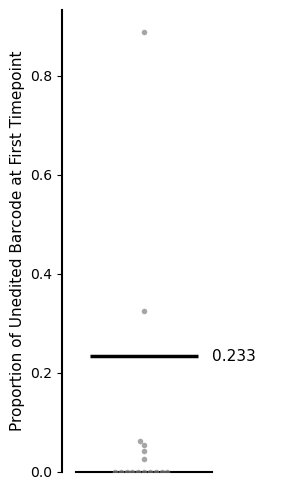

In [5]:
# ============================================
# PLOT 2: Proportion of Unedited Barcode per Fish
# ============================================

# Define unedited barcode
UNEDITED_BARCODE = "NONE_NONE_NONE_NONE_NONE_NONE_NONE_NONE_NONE_NONE"

# Calculate proportion for each fish-replicate combination
def calculate_proportion(group):
    total_reads = group['reads'].sum()
    unedited_reads = group[group['barcode'] == UNEDITED_BARCODE]['reads'].sum()
    return unedited_reads / total_reads if total_reads > 0 else 0

# Get proportion for each replicate
replicate_proportions = (
    df_sample1.groupby(['fish', 'replicate'], group_keys=False)
    .apply(calculate_proportion, include_groups=False)
    .reset_index(name='proportion_unedited')
)

# Average across replicates for each fish
fish_proportions = (
    replicate_proportions.groupby('fish')['proportion_unedited']
    .mean()
    .reset_index(name='proportion_unedited')
)

# Compute mean proportion (excluding zeros)
fish_proportions_nonzero = fish_proportions[fish_proportions['proportion_unedited'] > 0]
mean_proportion = fish_proportions_nonzero['proportion_unedited'].mean()

# Create plot
fig, ax = plt.subplots(figsize=(3, 5))

# Plot dots in gray using swarmplot with smaller size
sns.swarmplot(
    data=fish_proportions,
    x=[0] * len(fish_proportions),
    y='proportion_unedited',
    color='gray',
    size=4,
    alpha=0.7,
    ax=ax
)

# Add horizontal mean line
ax.hlines(y=mean_proportion, xmin=-0.2, xmax=0.2, color='black', linewidth=2.5, zorder=2)

# Add mean label
ax.text(
    x=0.25, y=mean_proportion, 
    s=f"{mean_proportion:.3f}", 
    va='center', ha='left', 
    fontsize=11, color='black'
)

# Set axis properties
ax.set_xlim(-0.3, 0.5)
ax.set_ylim(0, None)
ax.set_ylabel("Proportion of Unedited Barcode at First Timepoint", fontsize=11)
ax.set_xticks([])
ax.set_xlabel('')

# Clean up spines
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_visible(False)
ax.spines['left'].set_linewidth(1.5)
ax.spines['left'].set_color('black')

# Add shorter x-axis line at y=0
ax.plot([-0.25, 0.25], [0, 0], color='black', linewidth=1.5, clip_on=False)

plt.tight_layout()

plt.show()

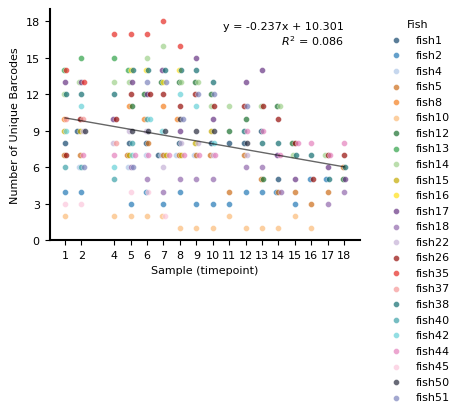

In [6]:
# ============================================
# PLOT 3: Barcode Count Over Time
# ============================================

# Count unique barcodes per fish at each timepoint
barcode_counts_time = (
    df.groupby(['fish', 'sample'])['barcode']
    .nunique()
    .reset_index(name='unique_barcode_count')
)

# Order fish numerically for legend
barcode_counts_time['fish_num'] = barcode_counts_time['fish'].str.extract(r'(\d+)').astype(int)
fish_order = sorted(barcode_counts_time['fish'].unique(), key=lambda x: int(x.replace('fish', '')))
barcode_counts_time['fish'] = pd.Categorical(barcode_counts_time['fish'], categories=fish_order, ordered=True)

# Calculate trendline (using all available data points WITHOUT offset)
x_data = barcode_counts_time['sample'].values
y_data = barcode_counts_time['unique_barcode_count'].values
slope, intercept, r_value, p_value, std_err = stats.linregress(x_data, y_data)
r_squared = r_value**2

# Create plot
fig, ax = plt.subplots(figsize=(4, 3))

# Calculate centering offset for each sample
offset_per_dot = 0.165
sample_max_count = {}  # Track max number of stacked dots per sample

# First pass: determine max offset per sample
for sample in barcode_counts_time['sample'].unique():
    sample_data = barcode_counts_time[barcode_counts_time['sample'] == sample]
    max_stack = 0
    for count_value in sample_data['unique_barcode_count'].unique():
        n_at_position = len(sample_data[sample_data['unique_barcode_count'] == count_value])
        max_stack = max(max_stack, n_at_position)
    sample_max_count[sample] = max_stack

# For each fish, stack overlapping values horizontally with centering
for fish in fish_order:
    fish_data = barcode_counts_time[barcode_counts_time['fish'] == fish]
    
    first_point = True  # Track first point for legend
    for idx, row in fish_data.iterrows():
        sample = row['sample']
        count = row['unique_barcode_count']
        
        # Count how many fish already plotted at this exact (sample, count) position
        already_plotted = barcode_counts_time[
            (barcode_counts_time['sample'] == sample) & 
            (barcode_counts_time['unique_barcode_count'] == count) &
            (barcode_counts_time['fish_num'] < row['fish_num'])
        ]
        
        # Total fish at this position
        total_at_position = len(barcode_counts_time[
            (barcode_counts_time['sample'] == sample) & 
            (barcode_counts_time['unique_barcode_count'] == count)
        ])
        
        # Apply horizontal offset with centering
        position_in_stack = len(already_plotted)
        total_width = (total_at_position - 1) * offset_per_dot
        centering_offset = -total_width / 2
        horizontal_offset = centering_offset + (position_in_stack * offset_per_dot)
        
        ax.scatter(
            sample + horizontal_offset,
            count,
            color=color_map.get(fish, 'gray'),
            s=18,
            alpha=0.7,
            label=fish if first_point else "",  # Only label once per fish
            edgecolors='white',
            linewidth=0.3
        )
        first_point = False

# Add trendline
x_line = np.linspace(x_data.min(), x_data.max(), 100)
y_line = slope * x_line + intercept
ax.plot(x_line, y_line, 'k', linewidth=1, alpha=0.6, zorder=1)

# Add equation and R-squared in top right
equation_text = f'y = {slope:.3f}x + {intercept:.3f}\n$R^2$ = {r_squared:.3f}'
ax.text(0.95, 0.95, equation_text,
        transform=ax.transAxes,
        fontsize=8,
        verticalalignment='top',
        horizontalalignment='right')
        #bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

# Format axes
ax.set_xlabel('Sample (timepoint)', fontsize=8)
ax.set_ylabel('Number of Unique Barcodes', fontsize=8)
ax.set_ylim(0, 19)
ax.set_yticks([0, 3, 6, 9, 12, 15, 18])
ax.tick_params(axis='y', labelsize=8)

# Set x-axis to show all samples (centered on actual sample values)
all_samples = sorted(df['sample'].unique())
ax.set_xticks(all_samples)
ax.set_xticklabels(all_samples, fontsize=8)

# Add legend
ax.legend(
    title='Fish',
    bbox_to_anchor=(1.05, 1),
    loc='upper left',
    frameon=False,
    fontsize=8,
    title_fontsize=8,
    ncol=1
)

# Clean up spines
for s in ['top', 'right']:
    ax.spines[s].set_visible(False)
ax.spines['left'].set_linewidth(1.5)
ax.spines['bottom'].set_linewidth(1.5)

#plt.savefig("ColoredScatter_tALL_v4.svg", bbox_inches='tight', transparent=True)
#plt.savefig("ColoredScatter_tALL_v4.png", dpi=600, bbox_inches='tight', transparent=True)
plt.show()

In [7]:
# ===================================
# PLOT 3.5: Connor's mixed linear model 
# ===================================

In [8]:
# Count unique barcodes per fish at each timepoint
barcode_counts_time = (
    df.groupby(['fish', 'time'])['barcode']
    .nunique()
    .reset_index(name='unique_barcode_count')
)

# Order fish numerically for legend
barcode_counts_time['fish_num'] = barcode_counts_time['fish'].str.extract(r'(\d+)').astype(int)
fish_order = sorted(barcode_counts_time['fish'].unique(), key=lambda x: int(x.replace('fish', '')))
barcode_counts_time['fish'] = pd.Categorical(barcode_counts_time['fish'], categories=fish_order, ordered=True)

In [9]:
# Function to compute Shannon diversity for a group
def shannon_diversity(group):
    counts = group['reads'].values
    total = counts.sum()
    if total == 0:
        return 0.0
    p = counts / total
    return -(p * np.log(p)).sum()

# Compute diversity per (fish, sample)
diversity = (
    df.groupby(['fish', 'time'])
    .apply(shannon_diversity, include_groups = False)
    .reset_index(name='diversity')
)

barcode_counts_time = barcode_counts_time.merge(diversity, on=['fish', 'time'])

In [10]:
barcode_counts_time["time_centered"] = (
    barcode_counts_time.groupby("fish_num")["time"].transform(lambda x: x - x.mean())
)

# mask = barcode_counts_time.groupby("fish_num")["sample"].transform("count") >= 3
# df_filtered = barcode_counts_time[mask].copy()

import statsmodels.formula.api as smf
model = smf.mixedlm(
    "diversity ~ time_centered",
    data=barcode_counts_time,
    groups=barcode_counts_time["fish_num"],
    re_formula="~time_centered"   # random intercept
)
result = model.fit()
print(result.summary())

               Mixed Linear Model Regression Results
Model:                 MixedLM     Dependent Variable:     diversity
No. Observations:      235         Method:                 REML     
No. Groups:            24          Scale:                  0.0803   
Min. group size:       3           Log-Likelihood:         -99.5892 
Max. group size:       16          Converged:              Yes      
Mean group size:       9.8                                          
--------------------------------------------------------------------
                          Coef.  Std.Err.   z    P>|z| [0.025 0.975]
--------------------------------------------------------------------
Intercept                  2.312    0.108 21.349 0.000  2.100  2.525
time_centered             -0.015    0.012 -1.292 0.196 -0.038  0.008
Group Var                  0.271    0.312                           
Group x time_centered Cov  0.007    0.024                           
time_centered Var          0.002    0.003         

/opt/anaconda3/envs/tm_test/lib/python3.11/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


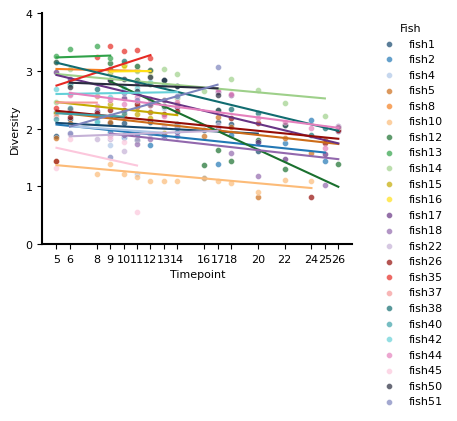

In [11]:
# Create plot
fig, ax = plt.subplots(figsize=(4, 3))

# Calculate centering offset for each sample
offset_per_dot = 0.165
sample_max_count = {}  # Track max number of stacked dots per sample

# First pass: determine max offset per sample
for sample in barcode_counts_time['time'].unique():
    sample_data = barcode_counts_time[barcode_counts_time['time'] == sample]
    max_stack = 0
    for count_value in sample_data['diversity'].unique():
        n_at_position = len(sample_data[sample_data['diversity'] == count_value])
        max_stack = max(max_stack, n_at_position)
    sample_max_count[sample] = max_stack

# For each fish, stack overlapping values horizontally with centering
for fish in fish_order:
    fish_data = barcode_counts_time[barcode_counts_time['fish'] == fish]
    
    first_point = True  # Track first point for legend
    for idx, row in fish_data.iterrows():
        sample = row['time']
        count = row['diversity']
        
        # Count how many fish already plotted at this exact (sample, count) position
        already_plotted = barcode_counts_time[
            (barcode_counts_time['time'] == sample) & 
            (barcode_counts_time['diversity'] == count) &
            (barcode_counts_time['fish_num'] < row['fish_num'])
        ]
        
        # Total fish at this position
        total_at_position = len(barcode_counts_time[
            (barcode_counts_time['time'] == sample) & 
            (barcode_counts_time['diversity'] == count)
        ])
        
        # Apply horizontal offset with centering
        position_in_stack = len(already_plotted)
        total_width = (total_at_position - 1) * offset_per_dot
        centering_offset = -total_width / 2
        horizontal_offset = centering_offset + (position_in_stack * offset_per_dot)
        
        ax.scatter(
            sample + horizontal_offset,
            count,
            color=color_map.get(fish, 'gray'),
            s=18,
            alpha=0.7,
            label=fish if first_point else "",  # Only label once per fish
            edgecolors='white',
            linewidth=0.3
        )
        first_point = False

# Fixed effect coefficients
intercept = result.params["Intercept"]
slope = result.params["time_centered"]

# Overlay fitted line for each fish, restricted to its domain
for fish, sub in barcode_counts_time.groupby("fish_num"):
    effects = result.random_effects[fish]
    ri = effects.get("Intercept", effects.get("Group", 0.0))
    rs = effects["time_centered"]

    group_mean = sub["time"].mean()
    x_vals = np.linspace(sub["time"].min(), sub["time"].max(), 100)
    x_centered = x_vals - group_mean
    y_pred = (intercept + ri) + (slope + rs) * x_centered
    plt.plot(x_vals, y_pred, color = color_map.get(f'fish{fish}', 'gray'))

# Format axes
ax.set_xlabel('Timepoint', fontsize=8)
ax.set_ylabel('Diversity', fontsize=8)
ax.set_ylim(0, 4)
ax.set_yticks([0, 1, 2, 3, 4])
ax.tick_params(axis='y', labelsize=8)

# Set x-axis to show all samples (centered on actual sample values)
all_samples = sorted(df['time'].unique())
ax.set_xticks(all_samples)
ax.set_xticklabels(all_samples, fontsize=8)

# Add legend
ax.legend(
    title='Fish',
    bbox_to_anchor=(1.05, 1),
    loc='upper left',
    frameon=False,
    fontsize=8,
    title_fontsize=8,
    ncol=1
)

# Clean up spines
for s in ['top', 'right']:
    ax.spines[s].set_visible(False)
ax.spines['left'].set_linewidth(1.5)
ax.spines['bottom'].set_linewidth(1.5)

plt.show()

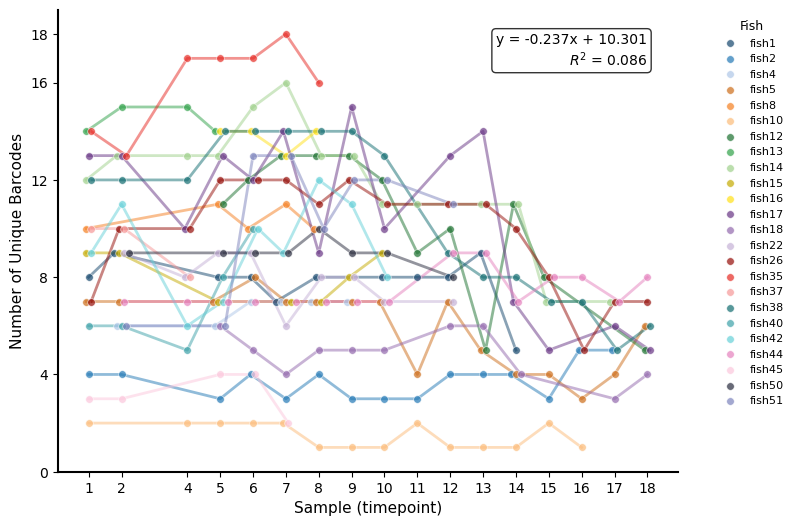

In [12]:
# ============================================
# PLOT 4: Barcode Count Over Time - Line Plot with Jitter
# ============================================

# Count unique barcodes per fish at each timepoint
barcode_counts_time = (
    df.groupby(['fish', 'sample'])['barcode']
    .nunique()
    .reset_index(name='unique_barcode_count')
)

# Order fish numerically for legend
barcode_counts_time['fish_num'] = barcode_counts_time['fish'].str.extract(r'(\d+)').astype(int)
fish_order = sorted(barcode_counts_time['fish'].unique(), key=lambda x: int(x.replace('fish', '')))
barcode_counts_time['fish'] = pd.Categorical(barcode_counts_time['fish'], categories=fish_order, ordered=True)

# Calculate trendline (using all available data points WITHOUT offset)
x_data = barcode_counts_time['sample'].values
y_data = barcode_counts_time['unique_barcode_count'].values
slope, intercept, r_value, p_value, std_err = stats.linregress(x_data, y_data)
r_squared = r_value**2

# Create plot
fig, ax = plt.subplots(figsize=(8, 6))

# Calculate centering offset for each sample
offset_per_dot = 0.15

# Store offset positions for each fish/sample combination
fish_offsets = {}

# Calculate offsets for all fish at all positions
for fish in fish_order:
    fish_data = barcode_counts_time[barcode_counts_time['fish'] == fish]
    fish_offsets[fish] = {}
    
    for idx, row in fish_data.iterrows():
        sample = row['sample']
        count = row['unique_barcode_count']
        
        # Count how many fish already plotted at this exact (sample, count) position
        already_plotted = barcode_counts_time[
            (barcode_counts_time['sample'] == sample) & 
            (barcode_counts_time['unique_barcode_count'] == count) &
            (barcode_counts_time['fish_num'] < row['fish_num'])
        ]
        
        # Total fish at this position
        total_at_position = len(barcode_counts_time[
            (barcode_counts_time['sample'] == sample) & 
            (barcode_counts_time['unique_barcode_count'] == count)
        ])
        
        # Apply horizontal offset with centering
        position_in_stack = len(already_plotted)
        total_width = (total_at_position - 1) * offset_per_dot
        centering_offset = -total_width / 2
        horizontal_offset = centering_offset + (position_in_stack * offset_per_dot)
        
        fish_offsets[fish][sample] = horizontal_offset

# Plot each fish with lines connecting samples
for fish in fish_order:
    fish_data = barcode_counts_time[barcode_counts_time['fish'] == fish].sort_values('sample')
    
    # Get offset x and y positions
    x_positions = []
    y_positions = []
    
    for idx, row in fish_data.iterrows():
        sample = row['sample']
        count = row['unique_barcode_count']
        offset = fish_offsets[fish][sample]
        
        x_positions.append(sample + offset)
        y_positions.append(count)
    
    # Plot line connecting offset points
    ax.plot(
        x_positions,
        y_positions,
        color=color_map.get(fish, 'gray'),
        alpha=0.5,
        linewidth=2
    )
    
    # Plot scatter points on top
    ax.scatter(
        x_positions,
        y_positions,
        color=color_map.get(fish, 'gray'),
        s=30,
        alpha=0.7,
        label=fish,
        edgecolors='white',
        linewidth=0.5,
        zorder=3  # Ensure points appear on top of lines
    )

# Add trendline (using non-offset data)
#x_line = np.linspace(x_data.min(), x_data.max(), 100)
#y_line = slope * x_line + intercept
#ax.plot(x_line, y_line, 'k--', linewidth=2, alpha=0.6, zorder=10)

# Add equation and R-squared in top right
equation_text = f'y = {slope:.3f}x + {intercept:.3f}\n$R^2$ = {r_squared:.3f}'
ax.text(0.95, 0.95, equation_text,
        transform=ax.transAxes,
        fontsize=10,
        verticalalignment='top',
        horizontalalignment='right',
        bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

# Format axes
ax.set_xlabel('Sample (timepoint)', fontsize=11)
ax.set_ylabel('Number of Unique Barcodes', fontsize=11)
ax.set_ylim(0, 19)
ax.set_yticks([0, 4, 8, 12, 16, 18])

# Set x-axis to show all samples (centered on actual sample values)
all_samples = sorted(df['sample'].unique())
ax.set_xticks(all_samples)
ax.set_xticklabels(all_samples)

# Add legend
ax.legend(
    title='Fish',
    bbox_to_anchor=(1.05, 1),
    loc='upper left',
    frameon=False,
    fontsize=8,
    title_fontsize=9,
    ncol=1
)

# Clean up spines
for s in ['top', 'right']:
    ax.spines[s].set_visible(False)
ax.spines['left'].set_linewidth(1.5)
ax.spines['bottom'].set_linewidth(1.5)

plt.show()

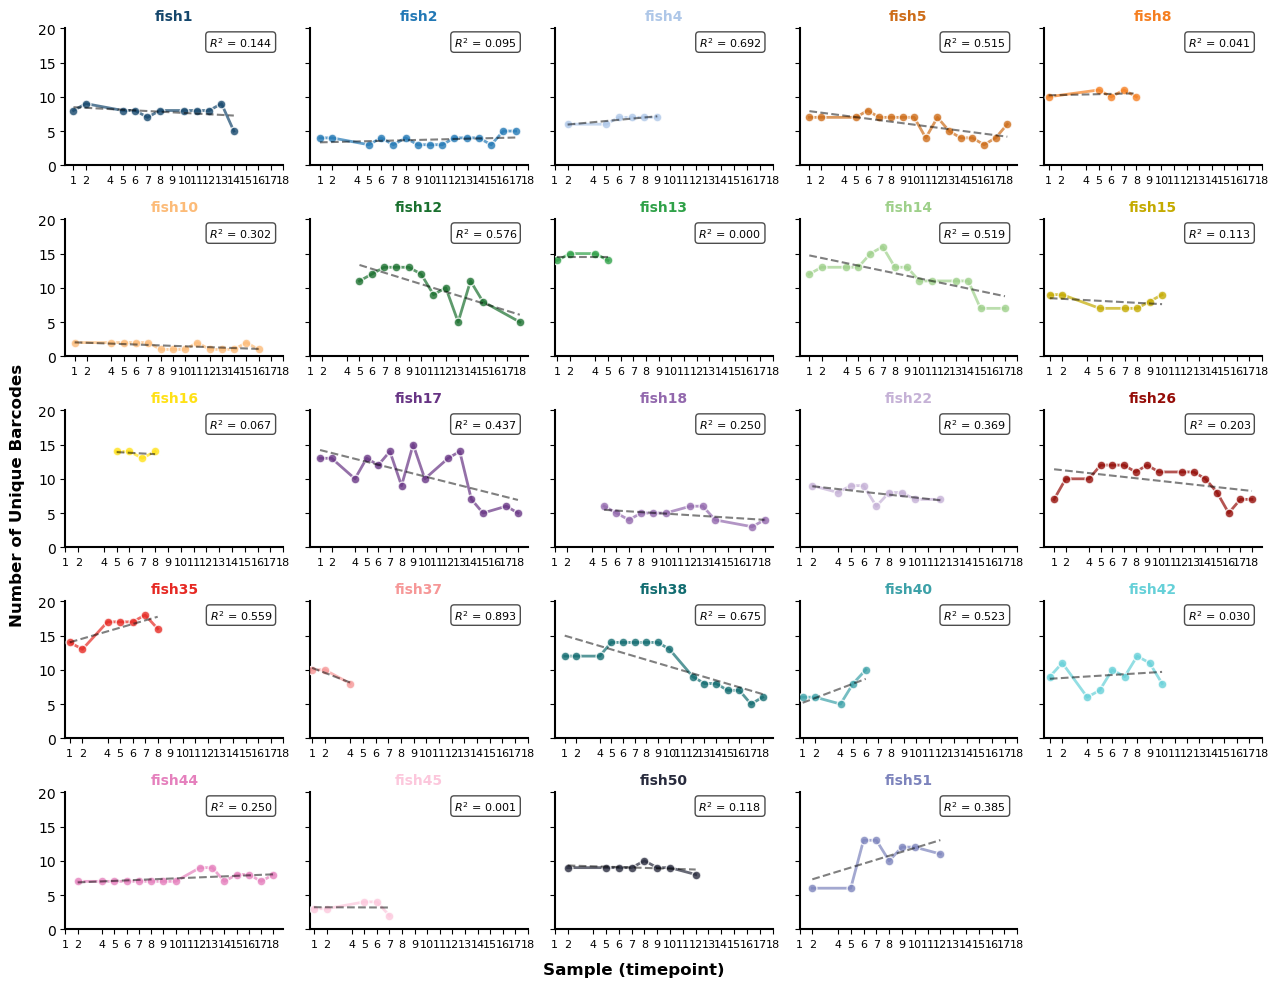

In [13]:
# ============================================
# PLOT 5: Barcode Count Over Time - Faceted by Fish
# ============================================
import math

# Count unique barcodes per fish at each timepoint
barcode_counts_time = (
    df.groupby(['fish', 'sample'])['barcode']
    .nunique()
    .reset_index(name='unique_barcode_count')
)

# Order fish numerically
barcode_counts_time['fish_num'] = barcode_counts_time['fish'].str.extract(r'(\d+)').astype(int)
fish_order = sorted(barcode_counts_time['fish'].unique(), key=lambda x: int(x.replace('fish', '')))

# Calculate grid dimensions
n_fish = len(fish_order)
n_cols = 5  # Number of columns in the grid
n_rows = math.ceil(n_fish / n_cols)

# Create subplots WITHOUT sharex
fig, axes = plt.subplots(n_rows, n_cols, figsize=(13, n_rows * 2), sharey=True)
axes = axes.flatten()  # Flatten to 1D array for easier indexing

# Get all samples for consistent x-axis
all_samples = sorted(df['sample'].unique())

# Plot each fish in its own facet
for idx, fish in enumerate(fish_order):
    ax = axes[idx]
    fish_data = barcode_counts_time[barcode_counts_time['fish'] == fish].sort_values('sample')
    
    # Plot line
    ax.plot(
        fish_data['sample'],
        fish_data['unique_barcode_count'],
        color=color_map.get(fish, 'gray'),
        linewidth=2,
        alpha=0.7
    )
    
    # Plot points
    ax.scatter(
        fish_data['sample'],
        fish_data['unique_barcode_count'],
        color=color_map.get(fish, 'gray'),
        s=40,
        alpha=0.8,
        edgecolors='white',
        linewidth=1,
        zorder=3
    )
    
    # Calculate trendline for this fish
    if len(fish_data) > 1:
        x_fish = fish_data['sample'].values
        y_fish = fish_data['unique_barcode_count'].values
        slope_fish, intercept_fish, r_fish, p_fish, se_fish = stats.linregress(x_fish, y_fish)
        
        # Add trendline
        x_line = np.linspace(x_fish.min(), x_fish.max(), 100)
        y_line = slope_fish * x_line + intercept_fish
        ax.plot(x_line, y_line, 'k--', linewidth=1.5, alpha=0.5, zorder=8)
        
        # Add R-squared to plot
        ax.text(0.95, 0.95, f'$R^2$ = {r_fish**2:.3f}',
                transform=ax.transAxes,
                fontsize=8,
                verticalalignment='top',
                horizontalalignment='right',
                bbox=dict(boxstyle='round', facecolor='white', alpha=0.7, pad=0.3))
    
    # Set title with fish name
    ax.set_title(fish, fontsize=10, fontweight='bold', color=color_map.get(fish, 'gray'))
    
    # Format axes
    ax.set_ylim(0, 20)
    ax.set_yticks([0, 5, 10, 15, 20])
    ax.set_xticks(all_samples)
    ax.set_xticklabels(all_samples, fontsize=8)
    
    # Clean up spines
    for s in ['top', 'right']:
        ax.spines[s].set_visible(False)
    ax.spines['left'].set_linewidth(1.5)
    ax.spines['bottom'].set_linewidth(1.5)

# Hide extra subplots if any
for idx in range(n_fish, len(axes)):
    axes[idx].set_visible(False)

# Add common labels
fig.text(0.5, 0.02, 'Sample (timepoint)', ha='center', fontsize=12, fontweight='bold')
fig.text(0.02, 0.5, 'Number of Unique Barcodes', va='center', rotation='vertical', fontsize=12, fontweight='bold')

plt.tight_layout(rect=[0.03, 0.03, 1, 1])
plt.savefig("ColoredLineFacets_tALL_v2.svg", bbox_inches='tight', transparent=True)
plt.savefig("ColoredLineFacets_tALL_v2.png", dpi=600, bbox_inches='tight', transparent=True)
plt.show()